# مرحله چهارم: مدل‌سازی (Modeling)

## مقدمه

در این مرحله از فرآیند CRISP-DM، از داده‌های آماده‌شده در مرحله قبل برای خوشه‌بندی مشتریان و ساخت مدل‌های طبقه‌بندی استفاده می‌کنیم.

هدف نهایی پروژه، شناسایی مشتریان پرریسک و انتخاب ۵۰۰ مشتری با بالاترین احتمال تعلق به گروه پرریسک است.

در این مرحله دو روش یادگیری ماشین استفاده می‌کنیم:

- Unsupervised Learning: برای خوشه‌بندی مشتریان با الگوریتم K-Means
- Supervised Learning: برای آموزش مدل‌های Classification با استفاده از برچسب‌های تولیدشده از خوشه‌بندی

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import joblib

In [7]:
import pandas as pd
customer_df = pd.read_csv("customer_prepared.csv")

scaled_df = pd.read_csv("customer_prepared_scaled.csv")

print("Customer Data:")
print(customer_df.head())

print("Scaled Data:")
print(scaled_df.head())

print("Customer Shape:", customer_df.shape)
print("Scaled Shape:", scaled_df.shape)

Customer Data:
   CustomerID  Recency  Frequency  Monetary  Frequency_Log  Monetary_Log
0     12346.0      326          1  77183.60       0.693147     11.253955
1     12347.0        2          7   3125.98       2.079442      8.047823
2     12348.0       75          4   1399.80       1.609438      7.244799
3     12349.0       19          1   1209.49       0.693147      7.098781
4     12350.0      310          1    174.20       0.693147      5.165928
Scaled Data:
    Recency  Frequency_Log  Monetary_Log
0  2.334305      -0.955104      4.009796
1 -0.905236       1.074301      1.423561
2 -0.175339       0.386260      0.775799
3 -0.735260      -0.955104      0.658013
4  2.174328      -0.955104     -0.901127
Customer Shape: (4338, 6)
Scaled Shape: (4338, 3)


**تحلیل:**

در این قسمت دو فایل ذخیره‌شده از مرحله سوم را بارگذاری می‌کنیم.

فایل اول شامل شناسه مشتری و ویژگی‌های RFM است و فایل دوم شامل ویژگی‌های استانداردشده برای اجرای الگوریتم K-Means است.

تعداد ردیف‌های دو فایل باید یکسان باشد؛ زیرا هر ردیف در هر دو فایل مربوط به یک مشتری است.

---

# بخش اول: شناخت مسئله و انتخاب الگوریتم

## **سؤال ۱: مسئله داده‌کاوی این پروژه از چه نوعی است؟**

**هدف از پرسیدن:**

تشخیص نوع مسئله برای انتخاب روش مناسب یادگیری ماشین.

**پاسخ:**

پروژه ما شامل دو نوع مسئله است:

1. Clustering برای گروه‌بندی مشتریان بر اساس رفتار خرید.
2. Classification برای پیش‌بینی احتمال تعلق مشتری به گروه پرریسک.

**تحلیل:**

از آنجا که دیتاست اولیه دارای برچسب آماده ریزش مشتری نیست، ابتدا از روش یادگیری بدون نظارت استفاده می‌کنیم.

پس از بررسی خوشه‌ها، یک برچسب اولیه برای مشتریان ایجاد می‌کنیم و سپس از روش یادگیری با نظارت برای آموزش مدل طبقه‌بندی استفاده می‌کنیم.


## **سؤال ۲: چرا از Clustering استفاده می‌کنیم؟**

**هدف از پرسیدن:**

توضیح دلیل استفاده از خوشه‌بندی در مسئله موردنظر.

**پاسخ:**

Clustering روشی از یادگیری بدون نظارت است که داده‌های مشابه را در گروه‌های مختلف قرار می‌دهد.

در پروژه ما از این روش برای تقسیم مشتریان بر اساس ویژگی‌های Recency، Frequency و Monetary استفاده می‌کنیم.

**تحلیل:**

خوشه‌بندی به ما کمک می‌کند مشتریانی را که رفتار خرید مشابهی دارند شناسایی کنیم.

برای مثال ممکن است یک خوشه شامل مشتریانی با خریدهای مکرر و جدید باشد و خوشه دیگر شامل مشتریانی باشد که مدت زیادی از آخرین خرید آن‌ها گذشته است.

## **سؤال ۳: چرا از Classification استفاده می‌کنیم؟**

**هدف از پرسیدن:**

مشخص کردن کاربرد طبقه‌بندی در ادامه پروژه.

**پاسخ:**

Classification روشی از یادگیری با نظارت است که با استفاده از داده‌های دارای برچسب، یک مدل برای پیش‌بینی کلاس داده‌های جدید آموزش می‌دهد.

در پروژه ما از برچسب‌های ساخته‌شده در مرحله خوشه‌بندی استفاده می‌کنیم تا مدل بتواند احتمال تعلق هر مشتری به گروه پرریسک را پیش‌بینی کند.

**تحلیل:**

با استفاده از Classification می‌توانیم مشتریان را بر اساس احتمال تعلق به گروه پرریسک رتبه‌بندی کنیم.

این رتبه‌بندی به انتخاب ۵۰۰ مشتری برای برنامه‌های بازاریابی و حفظ مشتری کمک می‌کند.

## **سؤال ۴: چه الگوریتم‌هایی برای این پروژه انتخاب می‌شوند؟**

**هدف از پرسیدن:**

انتخاب الگوریتم‌های مناسب برای خوشه‌بندی و طبقه‌بندی مشتریان.

**پاسخ:**

در این پروژه از الگوریتم‌های زیر استفاده می‌کنیم:

| نوع مسئله | الگوریتم |
|---|---|
| Clustering | K-Means |
| Classification | Logistic Regression |
| Classification | Decision Tree |
| Classification | Random Forest |

**تحلیل:**

الگوریتم K-Means برای گروه‌بندی مشتریان بر اساس شباهت رفتار خرید استفاده می‌شود.

سه الگوریتم Logistic Regression، Decision Tree و Random Forest نیز برای ساخت مدل‌های طبقه‌بندی انتخاب شده‌اند تا عملکرد آن‌ها را با یکدیگر مقایسه کنیم.

---


# بخش دوم: خوشه‌بندی مشتریان (Clustering)

## **سؤال ۵: چرا باید تعداد خوشه‌های مناسب را مشخص کنیم؟**

**هدف از پرسیدن:**

تعیین تعداد مناسب گروه‌های مشتریان برای اجرای الگوریتم K-Means.

**پاسخ:**

الگوریتم K-Means برای اجرا به تعداد خوشه‌ها نیاز دارد.

برای انتخاب تعداد مناسب خوشه‌ها از روش Elbow و معیار Silhouette استفاده می‌کنیم.


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
X = scaled_df[
    ["Recency", "Frequency_Log", "Monetary_Log"]
].copy()

print("Missing Values:")
print(X.isnull().sum())

X = X.astype(float)

inertia_values = []
silhouette_values = []

k_values = [2, 3, 4, 5, 6]

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    inertia_values.append(kmeans.inertia_)

    score = silhouette_score(X, labels)

    silhouette_values.append(score)


results = pd.DataFrame({
    "K": k_values,
    "Inertia": inertia_values,
    "Silhouette": silhouette_values
})

print(results)

Missing Values:
Recency          0
Frequency_Log    0
Monetary_Log     0
dtype: int64
   K      Inertia  Silhouette
0  2  6866.659902    0.407606
1  3  4287.875001    0.416803
2  4  3220.597401    0.381350
3  5  2733.070368    0.348391
4  6  2360.160435    0.341059


**تحلیل:**

در جدول خروجی دو معیار بررسی می‌شوند:

- Inertia: میزان فاصله داده‌ها از مرکز خوشه‌ها را نشان می‌دهد. معمولاً با افزایش تعداد خوشه‌ها کاهش پیدا می‌کند.
- Silhouette: میزان شباهت هر داده به خوشه خودش و تفاوت آن با خوشه‌های دیگر را نشان می‌دهد. مقدار بیشتر معمولاً نشان‌دهنده جداسازی بهتر خوشه‌هاست.

برای انتخاب تعداد خوشه مناسب، هر دو معیار را در کنار قابل‌تفسیر بودن خوشه‌ها بررسی می‌کنیم.


## **سؤال ۶: چگونه نمودار Elbow را رسم می‌کنیم؟**

**هدف از پرسیدن:**

مشاهده تغییرات Inertia برای انتخاب تعداد مناسب خوشه‌ها.


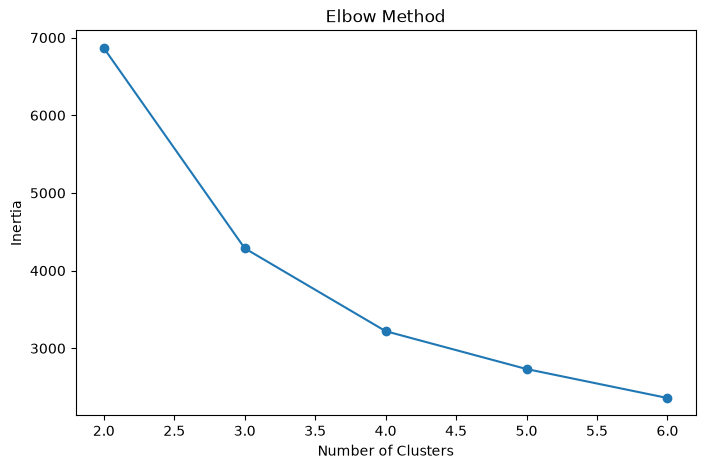

In [17]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

**تحلیل:**

در نمودار Elbow به دنبال نقطه‌ای هستیم که پس از آن کاهش Inertia کمتر و روند نمودار ملایم‌تر می‌شود.

این نقطه می‌تواند تعداد مناسبی برای خوشه‌ها پیشنهاد دهد؛ اما انتخاب نهایی باید با بررسی معیار Silhouette و ویژگی‌های واقعی مشتریان انجام شود.


## **سؤال ۷: چگونه نمودار Silhouette را رسم می‌کنیم؟**

**هدف از پرسیدن:**

مقایسه کیفیت خوشه‌بندی در تعداد خوشه‌های مختلف.


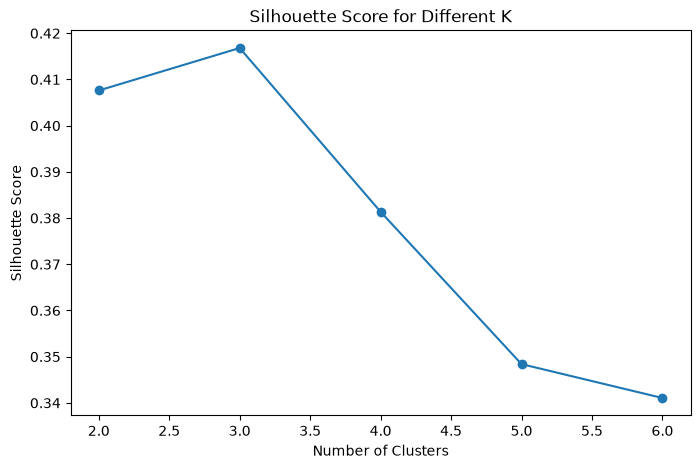

In [18]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K")

plt.show()

**تحلیل:**

مقدار بالاتر Silhouette معمولاً نشان‌دهنده خوشه‌هایی با جداسازی بهتر است.

با مقایسه نمودار Silhouette و Elbow می‌توانیم تعداد خوشه مناسب را انتخاب کنیم.

البته بالاترین مقدار Silhouette به‌تنهایی کافی نیست؛ خوشه‌ها باید از نظر رفتار خرید مشتریان نیز قابل‌تفسیر باشند.


## **سؤال ۸: چگونه مدل K-Means را با تعداد خوشه انتخاب‌شده آموزش می‌دهیم؟**

**هدف از پرسیدن:**

اجرای الگوریتم خوشه‌بندی و اختصاص یک شماره خوشه به هر مشتری.

**پاسخ:**

بعد از بررسی نمودارها، تعداد خوشه مناسب را انتخاب می‌کنیم.

در کد زیر مقدار `best_k` را با توجه به نتایج واقعی خودت تغییر بده.


In [19]:
best_k = 3

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

customer_df["Cluster"] = kmeans_model.fit_predict(X)

print(customer_df.head(10))

   CustomerID  Recency  Frequency  Monetary  Frequency_Log  Monetary_Log  \
0     12346.0      326          1  77183.60       0.693147     11.253955   
1     12347.0        2          7   3125.98       2.079442      8.047823   
2     12348.0       75          4   1399.80       1.609438      7.244799   
3     12349.0       19          1   1209.49       0.693147      7.098781   
4     12350.0      310          1    174.20       0.693147      5.165928   
5     12352.0       36          8   2218.14       2.197225      7.704875   
6     12353.0      204          1     89.00       0.693147      4.499810   
7     12354.0      232          1    585.02       0.693147      6.373354   
8     12355.0      214          1    373.00       0.693147      5.924256   
9     12356.0       23          3   2250.27       1.386294      7.719250   

   Cluster  
0        1  
1        1  
2        1  
3        0  
4        2  
5        1  
6        2  
7        2  
8        2  
9        1  


**تحلیل:**

پس از اجرای الگوریتم، هر مشتری به یکی از خوشه‌ها اختصاص داده می‌شود.

شماره خوشه‌ها فقط شناسه گروه‌ها هستند و به‌تنهایی نشان‌دهنده خوب یا بد بودن مشتری نیستند.

برای تشخیص گروه مشتریان پرریسک باید ویژگی‌های هر خوشه را بررسی کنیم.


## **سؤال ۹: ویژگی‌های هر خوشه چگونه بررسی می‌شوند؟**

**هدف از پرسیدن:**

شناخت رفتار خرید مشتریان در هر خوشه و شناسایی گروه‌های مختلف مشتریان.

**پاسخ:**

برای بررسی خوشه‌ها، میانگین ویژگی‌های RFM را در هر خوشه محاسبه می‌کنیم.


In [20]:
cluster_analysis = customer_df.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

print(cluster_analysis)

print(
    customer_df["Cluster"].value_counts().sort_index()
)

            Recency  Frequency     Monetary
Cluster                                    
0         54.539614   2.081159   455.010625
1         29.527259  10.015576  4226.103723
2        254.688008   1.386179   290.312359
Cluster
0    2070
1    1284
2     984
Name: count, dtype: int64


**تحلیل:**

با بررسی جدول می‌توانیم رفتار مشتریان هر خوشه را تشخیص دهیم.

- Recency بالا: مدت زیادی از آخرین خرید مشتری گذشته است.
- Frequency پایین: تعداد دفعات خرید مشتری کم است.
- Monetary پایین: ارزش خرید مشتری پایین است.

خوشه‌ای که این ویژگی‌ها را به شکل مشخص‌تری داشته باشد، می‌تواند گزینه مناسبی برای گروه مشتریان پرریسک باشد.


## **سؤال ۱۰: چگونه خوشه مشتریان پرریسک را مشخص می‌کنیم؟**

**هدف از پرسیدن:**

انتخاب خوشه‌ای که مشتریان آن احتمالاً نیاز بیشتری به اقدامات حفظ مشتری دارند.

**پاسخ:**

با توجه به جدول سؤال قبل، خوشه‌ای را انتخاب می‌کنیم که دارای Recency بالاتر و Frequency و Monetary پایین‌تر باشد.


In [21]:
print(cluster_analysis)
risk_cluster = 0

print("Selected Risk Cluster:", risk_cluster)

            Recency  Frequency     Monetary
Cluster                                    
0         54.539614   2.081159   455.010625
1         29.527259  10.015576  4226.103723
2        254.688008   1.386179   290.312359
Selected Risk Cluster: 0


**تحلیل:**

شماره خوشه‌ها در هر اجرای الگوریتم ممکن است متفاوت باشد؛ بنابراین نباید همیشه فرض کنیم خوشه شماره صفر یا یک، خوشه پرریسک است.

باید جدول میانگین ویژگی‌های خوشه‌ها را بررسی کنیم و شماره خوشه مناسب را به‌صورت دستی در `risk_cluster` قرار دهیم.


## **سؤال ۱۱: چگونه برای مشتریان برچسب اولیه (Pseudo-label) ایجاد می‌کنیم؟**

**هدف از پرسیدن:**

تبدیل نتیجه خوشه‌بندی به برچسب‌هایی که بتوان از آن‌ها در مرحله Classification استفاده کرد.

**پاسخ:**

به مشتریانی که در خوشه پرریسک قرار دارند برچسب ۱ و به سایر مشتریان برچسب صفر اختصاص می‌دهیم.


In [22]:
customer_df["PseudoLabel"] = (
    customer_df["Cluster"] == risk_cluster
).astype(int)

print(
    customer_df[
        ["CustomerID", "Cluster", "PseudoLabel"]
    ].head(10)
)
print(
    customer_df["PseudoLabel"].value_counts()
)

   CustomerID  Cluster  PseudoLabel
0     12346.0        1            0
1     12347.0        1            0
2     12348.0        1            0
3     12349.0        0            1
4     12350.0        2            0
5     12352.0        1            0
6     12353.0        2            0
7     12354.0        2            0
8     12355.0        2            0
9     12356.0        1            0
PseudoLabel
0    2268
1    2070
Name: count, dtype: int64


**تحلیل:**

در این مرحله یک ستون جدید به نام PseudoLabel ایجاد می‌شود.

- مقدار ۱: مشتری عضو خوشه انتخاب‌شده به‌عنوان گروه پرریسک است.
- مقدار ۰: مشتری عضو سایر خوشه‌هاست.

این برچسب‌ها از نتیجه خوشه‌بندی به دست آمده‌اند و برچسب واقعی ریزش مشتری نیستند.

---

# بخش سوم: آماده‌سازی برای Classification

## **سؤال ۱۲: چرا داده‌ها را به دو بخش Train و Test تقسیم می‌کنیم؟**

**هدف از پرسیدن:**

جدا کردن داده‌های آموزش و آزمون برای بررسی عملکرد مدل روی داده‌هایی که در زمان آموزش استفاده نشده‌اند.

**پاسخ:**

بخش Train برای آموزش مدل و بخش Test برای ارزیابی عملکرد آن استفاده می‌شود.

در این پروژه از نسبت ۸۰ به ۲۰ استفاده می‌کنیم.


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
customer_features = scaled_df[ ["Recency", "Frequency_Log", "Monetary_Log"] ]
customer_labels = customer_df["PseudoLabel"]
train_features, test_features, train_labels, test_labels = train_test_split( customer_features, customer_labels, test_size=0.2, random_state=42, stratify=customer_labels )

print("Training Customers:", len(train_features))
print("Testing Customers:", len(test_features))
print("Training Shape:", train_features.shape)
print("Testing Shape:", test_features.shape)


Training Customers: 3470
Testing Customers: 868
Training Shape: (3470, 3)
Testing Shape: (868, 3)


**تحلیل:**

۸۰ درصد داده‌ها برای آموزش مدل و ۲۰ درصد برای آزمون استفاده می‌شوند.

با استفاده از `stratify=y` تلاش می‌کنیم نسبت برچسب‌های صفر و یک در دو بخش Train و Test مشابه باشد.

نکته: چون برچسب‌ها از خوشه‌بندی ساخته شده‌اند، این آزمون عملکرد مدل در بازسازی برچسب‌های خوشه‌بندی را بررسی می‌کند، نه پیش‌بینی قطعی ریزش واقعی.


## **سؤال ۱۳: چه مدل‌هایی برای Classification آموزش می‌دهیم؟**

**هدف از پرسیدن:**

ساخت چند مدل مختلف برای مقایسه عملکرد و انتخاب مدل مناسب.

**پاسخ:**

در این پروژه سه الگوریتم زیر را آموزش می‌دهیم:

1. Logistic Regression
2. Decision Tree
3. Random Forest


In [36]:

logistic_model = LogisticRegression(
    max_iter=1000
)

decision_tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)


models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

**تحلیل:**

Logistic Regression یک مدل ساده و مناسب برای بررسی رابطه ویژگی‌ها با برچسب است.

Decision Tree با استفاده از قوانین تصمیم‌گیری مشتریان را دسته‌بندی می‌کند.

Random Forest از چندین درخت تصمیم استفاده می‌کند و نتیجه آن‌ها را با یکدیگر ترکیب می‌کند.

مقایسه این سه مدل به انتخاب مدل مناسب‌تر کمک می‌کند.


## **سؤال ۱۴: چگونه مدل‌ها را آموزش می‌دهیم؟**

**هدف از پرسیدن:**

آموزش الگوریتم‌های انتخاب‌شده با استفاده از داده‌های Train.


In [37]:

trained_models = {}

for model_name, classification_model in models.items():

    classification_model.fit(
        train_features,
        train_labels
    )

    trained_models[model_name] = classification_model

    print(model_name, "Trained Successfully!")

Logistic Regression Trained Successfully!
Decision Tree Trained Successfully!
Random Forest Trained Successfully!


**تحلیل:**

در این مرحله هر سه مدل با داده‌های آموزشی یاد می‌گیرند که مشتریان را در دو گروه صفر و یک قرار دهند.

پس از آموزش، مدل‌ها آماده پیش‌بینی روی داده‌های آزمون هستند.


## **سؤال ۱۵: چگونه مدل‌ها را روی داده‌های Test ارزیابی می‌کنیم؟**

**هدف از پرسیدن:**

بررسی میزان موفقیت هر مدل در پیش‌بینی برچسب مشتریان.

**پاسخ:**

برای ارزیابی مدل‌ها از معیارهای Accuracy، Precision، Recall و F1-Score استفاده می‌کنیم.


In [38]:

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

results = []

for model_name, classification_model in trained_models.items():

    
    predicted_labels = classification_model.predict(test_features)

    
    accuracy = accuracy_score(test_labels, predicted_labels)

    precision = precision_score(
        test_labels,
        predicted_labels,
        zero_division=0
    )

    recall = recall_score(
        test_labels,
        predicted_labels,
        zero_division=0
    )

    f1 = f1_score(
        test_labels,
        predicted_labels,
        zero_division=0
    )

    
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })


model_comparison = pd.DataFrame(results)


print(model_comparison)

                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression  0.880184   0.881773  0.864734  0.873171
1        Decision Tree  0.982719   0.985401  0.978261  0.981818
2        Random Forest  0.994240   1.000000  0.987923  0.993925


**تحلیل:**

هر معیار بخش متفاوتی از عملکرد مدل را نشان می‌دهد:

- Accuracy: درصد پیش‌بینی‌های درست.
- Precision: از مشتریانی که پرریسک پیش‌بینی شده‌اند، چه تعداد واقعاً طبق برچسب اولیه در گروه پرریسک بوده‌اند.
- Recall: از مشتریان دارای برچسب پرریسک، چه تعداد توسط مدل شناسایی شده‌اند.
- F1-Score: میانگین هماهنگ Precision و Recall.

در این پروژه Recall اهمیت زیادی دارد؛ زیرا می‌خواهیم تعداد بیشتری از مشتریان گروه پرریسک را شناسایی کنیم.


## **سؤال ۱۶: چگونه ماتریس درهم‌ریختگی (Confusion Matrix) را بررسی می‌کنیم؟**

**هدف از پرسیدن:**

بررسی جزئیات پیش‌بینی‌های درست و اشتباه هر مدل.


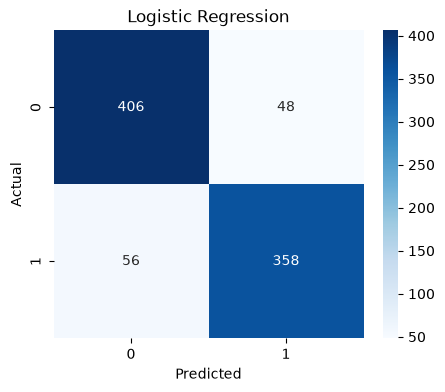

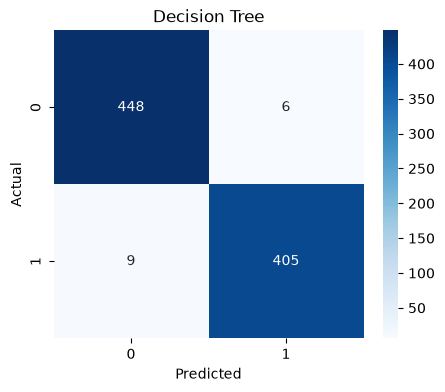

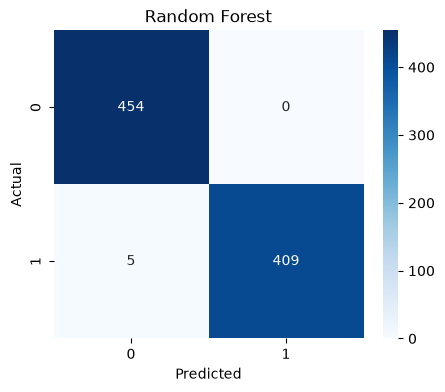

In [39]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix


for model_name, classification_model in trained_models.items():

    
    predicted_labels = classification_model.predict(test_features)

    
    confusion = confusion_matrix(
        test_labels,
        predicted_labels
    )

    
    plt.figure(figsize=(5, 4))

    
    sns.heatmap(
        confusion,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    
    plt.title(model_name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    
    plt.show()

**تحلیل:**

ماتریس درهم‌ریختگی چهار حالت را نشان می‌دهد:

- TP: مشتری پرریسک که درست شناسایی شده است.
- TN: مشتری غیرپرریسک که درست شناسایی شده است.
- FP: مشتری غیرپرریسک که اشتباهاً پرریسک پیش‌بینی شده است.
- FN: مشتری پرریسک که شناسایی نشده است.

برای پروژه ما کاهش FN اهمیت دارد؛ زیرا نمی‌خواهیم تعداد زیادی از مشتریان گروه پرریسک از دست بروند.


## **سؤال ۱۷: چگونه بهترین مدل را انتخاب می‌کنیم؟**

**هدف از پرسیدن:**

انتخاب مدلی که برای شناسایی مشتریان پرریسک عملکرد مناسب‌تری دارد.

**پاسخ:**

در این پروژه Recall و F1-Score را در کنار یکدیگر بررسی می‌کنیم.


In [40]:

model_comparison = model_comparison.sort_values(
    by=["Recall", "F1-Score"],
    ascending=False
)

print(model_comparison)

best_model_name = model_comparison.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

                 Model  Accuracy  Precision    Recall  F1-Score
2        Random Forest  0.994240   1.000000  0.987923  0.993925
1        Decision Tree  0.982719   0.985401  0.978261  0.981818
0  Logistic Regression  0.880184   0.881773  0.864734  0.873171
Best Model: Random Forest


**تحلیل:**

مدلی که Recall بالاتری داشته باشد، تعداد بیشتری از مشتریان دارای برچسب پرریسک را شناسایی می‌کند.

F1-Score نیز کمک می‌کند Precision و Recall را هم‌زمان در نظر بگیریم.

مدل منتخب باید علاوه بر معیارهای آماری، از نظر کاربردی نیز مناسب باشد.


## **سؤال ۱۸: چگونه ۵۰۰ مشتری با بالاترین احتمال تعلق به گروه پرریسک را انتخاب می‌کنیم؟**

**هدف از پرسیدن:**

شناسایی مشتریانی که بالاترین احتمال تعلق به گروه پرریسک را دارند تا برای اقدامات بازاریابی و حفظ مشتری انتخاب شوند.

**پاسخ:**

با استفاده از مدل منتخب، احتمال تعلق هر مشتری به کلاس یک را محاسبه می‌کنیم و مشتریان را بر اساس این احتمال مرتب می‌کنیم.


In [41]:

risk_class_index = list(best_model.classes_).index(1)


customer_df["RiskProbability"] = (
    best_model.predict_proba(customer_features)[
        :, risk_class_index
    ]
)

top_500_customers = customer_df.sort_values(
    by="RiskProbability",
    ascending=False
).head(500)


print("Top 500 At-Risk Customers:")

print(
    top_500_customers[
        [
            "CustomerID",
            "Recency",
            "Frequency",
            "Monetary",
            "RiskProbability"
        ]
    ]
)

Top 500 At-Risk Customers:
      CustomerID  Recency  Frequency  Monetary  RiskProbability
4316     18255.0       89          1    103.30              1.0
4315     18252.0       51          2    397.82              1.0
4312     18249.0       17          1     73.50              1.0
4311     18248.0      123          2    577.22              1.0
4310     18246.0       24          2    596.10              1.0
...          ...      ...        ...       ...              ...
3446     17048.0      118          3    729.55              1.0
3445     17047.0       85          3    770.09              1.0
3443     17045.0      113          3    320.64              1.0
527      13037.0      138          3    661.57              1.0
526      13035.0       74          2    761.08              1.0

[500 rows x 5 columns]


**تحلیل:**

در پایان مدل منتخب، نتایج مقایسه الگوریتم‌ها و فهرست ۵۰۰ مشتری منتخب ذخیره می‌شوند.

این فایل‌ها برای ارائه نتایج و ادامه پروژه مورد استفاده قرار می‌گیرند.

---

# نتیجه‌گیری مرحله چهارم

در این مرحله ابتدا با استفاده از الگوریتم K-Means مشتریان بر اساس رفتار خرید خوشه‌بندی شدند.

سپس با بررسی ویژگی‌های هر خوشه، گروه مشتریان پرریسک شناسایی شد و برای آن‌ها برچسب اولیه (Pseudo-label) ایجاد گردید.

در ادامه سه مدل Logistic Regression، Decision Tree و Random Forest آموزش داده شدند و عملکرد آن‌ها با معیارهای مختلف مورد مقایسه قرار گرفت.

در نهایت بهترین مدل انتخاب شد و ۵۰۰ مشتری با بالاترین احتمال تعلق به گروه پرریسک استخراج شدند.
